# Day 5: Famous Architectures (LeNet, VGG, ResNet)
**Deep Learning Internship, Phase 2 (CNNs)**

Goals: (1) understand LeNet, VGG and ResNet, (2) write a **residual block** and a mini-ResNet for CIFAR-10, (3) compare it with a plain CNN on parameters and accuracy, (4) inspect `torchvision.models.resnet18`.

- **LeNet:** the first CNN (digit recognition): conv, pool, conv, pool, fully connected.
- **VGG:** deep stacks of small 3x3 convolutions.
- **ResNet:** skip connections: the block outputs `F(x) + x`. The layers only have to learn the *change* (the residual), so very deep networks train well.

> Use Colab with a **T4 GPU**. On a CPU, set `EPOCHS = 3` first.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

torch.manual_seed(42)
np.random.seed(42)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

Using device: cuda


In [2]:
CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD = (0.2470, 0.2435, 0.2616)

plain_tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize(CIFAR_MEAN, CIFAR_STD)])
aug_tf = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomCrop(32, padding=4),
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD),
])

train_plain = datasets.CIFAR10("./data", train=True, download=True, transform=plain_tf)
train_aug = datasets.CIFAR10("./data", train=True, download=True, transform=aug_tf)
test_set = datasets.CIFAR10("./data", train=False, download=True, transform=plain_tf)
classes = train_plain.classes

# Same 45,000 / 5,000 split for both versions
perm = torch.randperm(50000, generator=torch.Generator().manual_seed(42)).tolist()
train_idx, val_idx = perm[:45000], perm[45000:]

val_set = Subset(train_plain, val_idx)             # validation: never augmented
train_set_plain = Subset(train_plain, train_idx)   # training without augmentation
train_set_aug = Subset(train_aug, train_idx)       # augmentation ONLY on training images

BATCH_SIZE = 128
train_loader_plain = DataLoader(train_set_plain, batch_size=BATCH_SIZE, shuffle=True)
train_loader_aug = DataLoader(train_set_aug, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE)

print("train / val / test:", len(train_set_aug), len(val_set), len(test_set))
print(classes)

100%|██████████| 170M/170M [00:15<00:00, 11.1MB/s]


train / val / test: 45000 5000 10000
['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [3]:
def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train() if training else model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = criterion(out, y)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            total += x.size(0)
    return total_loss / total, correct / total


def fit(model, train_loader, epochs, lr=1e-3, use_scheduler=False):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs) if use_scheduler else None
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_val, best_state = 0.0, None
    start = time.time()
    for epoch in range(1, epochs + 1):
        tr_loss, tr_acc = run_epoch(model, train_loader, criterion, optimizer)
        va_loss, va_acc = run_epoch(model, val_loader, criterion)
        if scheduler:
            scheduler.step()
        history["train_loss"].append(tr_loss); history["val_loss"].append(va_loss)
        history["train_acc"].append(tr_acc);   history["val_acc"].append(va_acc)
        if va_acc > best_val:
            best_val = va_acc
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        print(f"Epoch {epoch:2d}/{epochs} | train loss {tr_loss:.4f} acc {tr_acc:.4f} "
              f"| val loss {va_loss:.4f} acc {va_acc:.4f}")
    history["time"] = time.time() - start
    return history, best_state

## 1. Plain CNN (baseline from Day 4)

In [4]:
class PlainCNN(nn.Module):
    def __init__(self, dropout=0.3):
        super().__init__()

        def block(i, o):
            return [nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(), nn.MaxPool2d(2)]

        self.features = nn.Sequential(*block(3, 32), *block(32, 64), *block(64, 128))
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 256), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(256, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

## 2. Residual block and mini-ResNet
A residual block computes `out = ReLU(F(x) + shortcut(x))`, where `F` is two 3x3 convolutions with batch norm.
If the shape changes (stride 2 or more channels), the shortcut uses a 1x1 convolution to match it.
The `skip` flag lets us switch the skip connection off, for a fair comparison.

Shape: `3x32x32 -> 32x32x32 -> 32x32x32 -> 64x16x16 -> 128x8x8 -> pool -> 128 -> 10`

In [5]:
class ResidualBlock(nn.Module):
    def __init__(self, in_c, out_c, stride=1, skip=True):
        super().__init__()
        self.skip = skip
        self.conv1 = nn.Conv2d(in_c, out_c, 3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_c)
        self.conv2 = nn.Conv2d(out_c, out_c, 3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_c)
        self.relu = nn.ReLU()
        if stride != 1 or in_c != out_c:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_c, out_c, 1, stride=stride, bias=False),
                nn.BatchNorm2d(out_c),
            )
        else:
            self.shortcut = nn.Identity()

    def forward(self, x):
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))          # F(x)
        if self.skip:
            out = out + self.shortcut(x)         # F(x) + x
        return self.relu(out)


class MiniResNet(nn.Module):
    def __init__(self, skip=True):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, 32, 3, padding=1, bias=False), nn.BatchNorm2d(32), nn.ReLU())
        self.layers = nn.Sequential(
            ResidualBlock(32, 32, skip=skip),
            ResidualBlock(32, 64, stride=2, skip=skip),
            ResidualBlock(64, 128, stride=2, skip=skip),
        )
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(128, 10))

    def forward(self, x):
        return self.head(self.layers(self.stem(x)))


# Shape check
net = MiniResNet().to(device).eval()
x = torch.randn(1, 3, 32, 32).to(device)
with torch.no_grad():
    x = net.stem(x); print("stem            ->", tuple(x.shape))
    for i, blk in enumerate(net.layers, 1):
        x = blk(x); print(f"res block {i}     ->", tuple(x.shape))
    x = net.head(x); print("head            ->", tuple(x.shape))
print("MiniResNet parameters:", f"{count_params(net):,}")
print("PlainCNN parameters:  ", f"{count_params(PlainCNN()):,}")

stem            -> (1, 32, 32, 32)
res block 1     -> (1, 32, 32, 32)
res block 2     -> (1, 64, 16, 16)
res block 3     -> (1, 128, 8, 8)
head            -> (1, 10)
MiniResNet parameters: 308,650
PlainCNN parameters:   620,810


## 3. Train and compare (with augmentation, same seed)

In [6]:
EPOCHS = 15       # use 3 on a CPU first
criterion = nn.CrossEntropyLoss()
results = {}


def experiment(name, model):
    print(f"\n=== {name} ===")
    torch.manual_seed(42)
    model = model.to(device)
    hist, state = fit(model, train_loader_aug, EPOCHS)
    model.load_state_dict(state)
    _, test_acc = run_epoch(model, test_loader, criterion)
    results[name] = {"hist": hist, "test_acc": test_acc, "params": count_params(model)}
    print(f"Test accuracy: {test_acc:.4f}")


experiment("Plain CNN", PlainCNN())
experiment("Mini-ResNet", MiniResNet(skip=True))


=== Plain CNN ===
Epoch  1/15 | train loss 1.5484 acc 0.4327 | val loss 1.2098 acc 0.5716
Epoch  2/15 | train loss 1.2003 acc 0.5706 | val loss 1.0138 acc 0.6406
Epoch  3/15 | train loss 1.0645 acc 0.6219 | val loss 0.8884 acc 0.6810
Epoch  4/15 | train loss 0.9823 acc 0.6537 | val loss 0.8596 acc 0.6940
Epoch  5/15 | train loss 0.9256 acc 0.6748 | val loss 0.8649 acc 0.6948
Epoch  6/15 | train loss 0.8785 acc 0.6915 | val loss 0.7319 acc 0.7366
Epoch  7/15 | train loss 0.8447 acc 0.7045 | val loss 0.7296 acc 0.7448
Epoch  8/15 | train loss 0.8087 acc 0.7167 | val loss 0.7177 acc 0.7518
Epoch  9/15 | train loss 0.7818 acc 0.7273 | val loss 0.7082 acc 0.7498
Epoch 10/15 | train loss 0.7590 acc 0.7369 | val loss 0.6231 acc 0.7842
Epoch 11/15 | train loss 0.7405 acc 0.7428 | val loss 0.6881 acc 0.7584
Epoch 12/15 | train loss 0.7125 acc 0.7526 | val loss 0.6184 acc 0.7810
Epoch 13/15 | train loss 0.6985 acc 0.7585 | val loss 0.6141 acc 0.7828
Epoch 14/15 | train loss 0.6836 acc 0.7618 | 

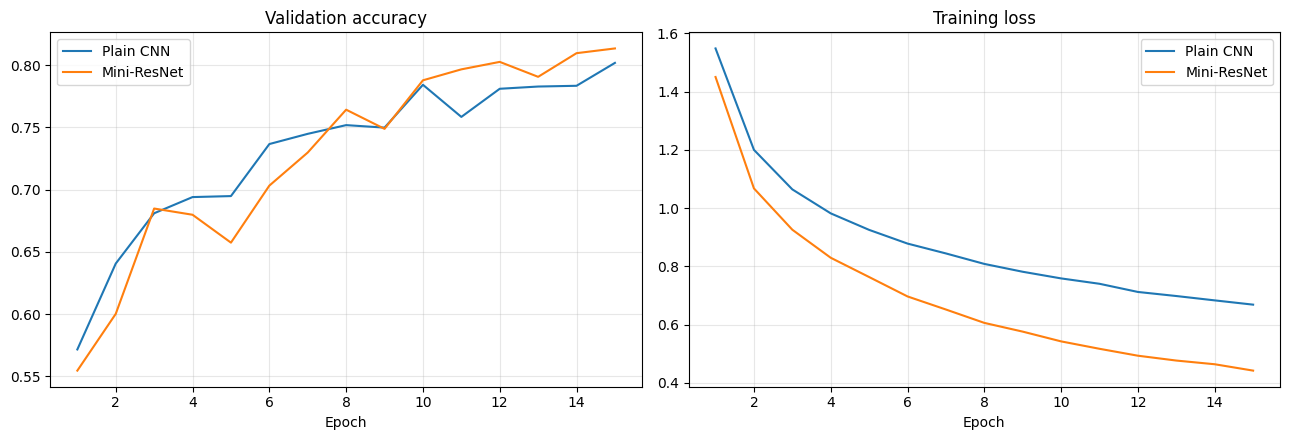

Model                        Params  Best val acc  Test acc  Time (s)
Plain CNN                   620,810        0.8018    0.7978     307.1
Mini-ResNet                 308,650        0.8134    0.8151     401.3


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ep = range(1, EPOCHS + 1)
for name, r in results.items():
    axes[0].plot(ep, r["hist"]["val_acc"], label=name)
    axes[1].plot(ep, r["hist"]["train_loss"], label=name)
axes[0].set_title("Validation accuracy"); axes[1].set_title("Training loss")
for ax in axes:
    ax.set_xlabel("Epoch"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"{'Model':<24} {'Params':>10} {'Best val acc':>13} {'Test acc':>9} {'Time (s)':>9}")
for name, r in results.items():
    print(f"{name:<24} {r['params']:>10,} {max(r['hist']['val_acc']):>13.4f} {r['test_acc']:>9.4f} {r['hist']['time']:>9.1f}")

## 4. Optional ablation: the same network without the skip connections
Everything is identical except `out = F(x)` instead of `F(x) + x`. This isolates what the skip connection adds.
(With only 3 blocks the difference is small; it grows a lot as networks get deeper.)

In [8]:
experiment("Mini-ResNet, no skip", MiniResNet(skip=False))

for name, r in results.items():
    print(f"{name:<24} test acc {r['test_acc']:.4f} | params {r['params']:,}")


=== Mini-ResNet, no skip ===
Epoch  1/15 | train loss 1.4468 acc 0.4693 | val loss 1.3617 acc 0.5060
Epoch  2/15 | train loss 1.0501 acc 0.6247 | val loss 1.3269 acc 0.5546
Epoch  3/15 | train loss 0.9039 acc 0.6786 | val loss 0.9365 acc 0.6682
Epoch  4/15 | train loss 0.8104 acc 0.7138 | val loss 0.9159 acc 0.6878
Epoch  5/15 | train loss 0.7343 acc 0.7434 | val loss 0.8240 acc 0.7092
Epoch  6/15 | train loss 0.6737 acc 0.7642 | val loss 0.8427 acc 0.7054
Epoch  7/15 | train loss 0.6278 acc 0.7797 | val loss 0.7479 acc 0.7402
Epoch  8/15 | train loss 0.5887 acc 0.7950 | val loss 0.7021 acc 0.7574
Epoch  9/15 | train loss 0.5575 acc 0.8065 | val loss 0.7035 acc 0.7604
Epoch 10/15 | train loss 0.5237 acc 0.8196 | val loss 0.6284 acc 0.7832
Epoch 11/15 | train loss 0.5020 acc 0.8268 | val loss 0.5789 acc 0.8020
Epoch 12/15 | train loss 0.4776 acc 0.8340 | val loss 0.6504 acc 0.7810
Epoch 13/15 | train loss 0.4646 acc 0.8414 | val loss 0.5665 acc 0.8088
Epoch 14/15 | train loss 0.4495 ac

## 5. LeNet and ResNet18 (structure and parameter count)
We only inspect these; no training is needed. `weights=None` builds the architecture without downloading anything.

In [9]:
class LeNet(nn.Module):
    # Classic LeNet-5 style network, adapted to 3x32x32 input
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(3, 6, 5), nn.ReLU(), nn.MaxPool2d(2),      # 6x28x28 -> 6x14x14
            nn.Conv2d(6, 16, 5), nn.ReLU(), nn.MaxPool2d(2),     # 16x10x10 -> 16x5x5
            nn.Flatten(),
            nn.Linear(16 * 5 * 5, 120), nn.ReLU(),
            nn.Linear(120, 84), nn.ReLU(),
            nn.Linear(84, 10),
        )

    def forward(self, x):
        return self.net(x)


from torchvision import models
resnet18 = models.resnet18(weights=None)
print(resnet18)

n_blocks = sum(isinstance(m, models.resnet.BasicBlock) for m in resnet18.modules())
print("\nResNet18 residual blocks:", n_blocks)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

In [10]:
print(f"{'Architecture':<14} {'Parameters':>12}")
print(f"{'LeNet':<14} {count_params(LeNet()):>12,}")
print(f"{'Plain CNN':<14} {results['Plain CNN']['params']:>12,}")
print(f"{'Mini-ResNet':<14} {results['Mini-ResNet']['params']:>12,}")
print(f"{'ResNet18':<14} {count_params(resnet18):>12,}")

Architecture     Parameters
LeNet                62,006
Plain CNN           620,810
Mini-ResNet         308,650
ResNet18         11,689,512


## Summary (rewrite in your own words)
- LeNet was the first CNN; VGG showed that deep stacks of 3x3 convolutions work well; ResNet added skip connections.
- A residual block outputs `F(x) + x`. The layers learn only the residual, and the skip path lets gradients flow straight back, so very deep networks can train.
- Deeper is not automatically better: without skip connections, very deep plain networks become harder to train and can get worse.
- Compare the table: parameters and accuracy of the plain CNN vs the mini-ResNet, and think about what the skip connection and global average pooling change.
- ResNet18 has 8 residual blocks and roughly 11.7 million parameters, so it is far bigger than our mini-ResNet.
- Next (Day 6): transfer learning with a pretrained ResNet18.